In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile

from google.colab import files
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Unzip the datasets if they exist
try:
    with zipfile.ZipFile("olist_orders_dataset.csv.zip", 'r') as zip_ref:
        zip_ref.extractall(".")
    print("Unzipped olist_orders_dataset.csv.zip successfully!")
except FileNotFoundError:
    print("Could not find olist_orders_dataset.csv.zip, please make sure it is uploaded.")

try:
    # Try extracting the original zip or the uploaded copy
    zip_name = "olist_order_items_dataset.csv.zip"
    try:
        with zipfile.ZipFile(zip_name, 'r') as zip_ref:
            zip_ref.extractall(".")
    except FileNotFoundError:
        zip_name = "olist_order_items_dataset.csv (1).zip"
        with zipfile.ZipFile(zip_name, 'r') as zip_ref:
            zip_ref.extractall(".")
    print(f"Unzipped {zip_name} successfully!")
except FileNotFoundError:
    print("Could not find olist_order_items_dataset.csv.zip, please make sure it is uploaded.")

# Load the extracted CSV files
orders = pd.read_csv("olist_orders_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")

print("Orders dataset shape:", orders.shape)
print("Order items dataset shape:", items.shape)

display(orders.head())
display(items.head())

Unzipped olist_orders_dataset.csv.zip successfully!
Unzipped olist_order_items_dataset.csv.zip successfully!
Orders dataset shape: (99441, 8)
Order items dataset shape: (112650, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [3]:
print("Orders dataset information:")
orders.info()

print("\nMissing values in orders:")
print(orders.isnull().sum())

print("\nMissing values in order items:")
print(items.isnull().sum())

print("\nDuplicate order rows:", orders.duplicated().sum())
print("Duplicate order-item rows:", items.duplicated().sum())

print("\nOrder status counts:")
print(orders["order_status"].value_counts(dropna=False))

print("\nNumerical summary:")
display(items[["price", "freight_value"]].describe())

Orders dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Missing values in orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_c

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [4]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Check missing values after conversion
print("Missing values after date conversion:")
print(orders[date_columns].isnull().sum())

# Select delivered orders with valid purchase and delivery dates
delivered = orders[
    (orders["order_status"] == "delivered") &
    orders["order_purchase_timestamp"].notna() &
    orders["order_delivered_customer_date"].notna()
].copy()

print("Delivered orders available for analysis:", len(delivered))

Missing values after date conversion:
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
Delivered orders available for analysis: 96470


In [5]:
# Remove exact duplicate rows
orders = orders.drop_duplicates()
items = items.drop_duplicates()

# Check duplicate business keys
print(
    "Duplicate order IDs:",
    orders["order_id"].duplicated().sum())

print(
    "Duplicate order-item keys:",
    items.duplicated(
        subset=["order_id", "order_item_id"]).sum())

Duplicate order IDs: 0
Duplicate order-item keys: 0


In [6]:
# Convert columns to numeric
for col in ["price", "freight_value"]:
    items[col] = pd.to_numeric(items[col], errors="coerce")

# Check invalid negative values
print("Negative prices:", (items["price"] < 0).sum())
print("Negative freight values:", (items["freight_value"] < 0).sum())

# Display rows requiring investigation
print("Rows with negative prices:")
display(items[items["price"] < 0].head())

print("Rows with negative freight values:")
display(items[items["freight_value"] < 0].head())

Negative prices: 0
Negative freight values: 0
Rows with negative prices:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value


Rows with negative freight values:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value


In [7]:
# Standardize order-status text
orders["order_status"] = (
    orders["order_status"]
    .astype("string")
    .str.strip()
    .str.lower())

# Calculate delivery duration in days
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Identify impossible negative delivery durations
print(
    "Negative delivery durations:",
    (delivered["delivery_days"] < 0).sum())

display(delivered[["order_id", "delivery_days"]].head())

Negative delivery durations: 0


,order_id,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877


In [8]:
# Calculate quartiles and IQR
Q1 = delivered["delivery_days"].quantile(0.25)
Q3 = delivered["delivery_days"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag outliers
delivered["delivery_time_outlier"] = (
    (delivered["delivery_days"] < lower_bound) |
    (delivered["delivery_days"] > upper_bound))

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print(
    "Number of outliers:",
    delivered["delivery_time_outlier"].sum())

# Display some flagged rows
display(
    delivered[delivered["delivery_time_outlier"]].head())

Lower bound: -6.664764178240739
Upper bound: 29.15115017361111
Number of outliers: 4896


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delivery_time_outlier
29,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,delivered,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13,30.401898,True
35,8563039e855156e48fccee4d611a3196,5f16605299d698660e0606f7eae2d2f9,delivered,2018-02-17 15:59:46,2018-02-17 16:15:34,2018-02-20 23:03:56,2018-03-20 00:59:25,2018-03-20,30.374757,True
41,6ea2f835b4556291ffdc53fa0b3b95e8,c7340080e394356141681bd4c9b8fe31,delivered,2017-11-24 21:27:48,2017-11-25 00:21:09,2017-12-13 21:14:05,2017-12-28 18:59:23,2017-12-21,33.896933,True
97,6a0a8bfbbe700284feb0845d95e0867f,68451b39b1314302c08c65a29f1140fc,delivered,2017-11-22 11:32:22,2017-11-22 11:46:50,2017-11-27 13:39:35,2017-12-28 19:43:00,2017-12-11,36.340718,True
110,9d531c565e28c3e0d756192f84d8731f,d4faa220408c20e53595d2950f361f3b,delivered,2017-11-28 21:00:44,2017-12-01 09:31:15,2017-12-14 20:37:43,2018-01-23 21:38:52,2017-12-22,56.026481,True


In [9]:
# Calculate estimated delivery duration
delivered["estimated_delivery_days"] = (
    delivered["order_estimated_delivery_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Identify late deliveries
delivered["late_delivery"] = (
    delivered["order_delivered_customer_date"] >
    delivered["order_estimated_delivery_date"]
).astype(int)

print("Delivery analysis:")
display(
    delivered[
        [
            "order_id",
            "delivery_days",
            "estimated_delivery_days",
            "late_delivery"
        ]
    ].head() )

print("\nLate delivery counts:")
print(delivered["late_delivery"].value_counts())

Delivery analysis:


,order_id,delivery_days,estimated_delivery_days,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,15.544063,0
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,19.137766,0
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,26.639711,0
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,26.188819,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,12.112049,0



Late delivery counts:
late_delivery
0    88644
1     7826
Name: count, dtype: int64


In [10]:
# Select numeric data for scaling
numeric_data = delivered[["delivery_days"]].dropna()

# Min-Max normalization: values between 0 and 1
minmax_scaler = MinMaxScaler()
normalized_data = minmax_scaler.fit_transform(numeric_data)

# Standardization: approximately zero mean and unit variance
standard_scaler = StandardScaler()
standardized_data = standard_scaler.fit_transform(numeric_data)

# Store scaled values for demonstration
scaled_results = pd.DataFrame({
    "Original_Delivery_Days": numeric_data["delivery_days"].values,
    "MinMax_Normalized": normalized_data.flatten(),
    "Standardized": standardized_data.flatten() })

display(scaled_results.head())

,Original_Delivery_Days,MinMax_Normalized,Standardized
0,8.436574,0.037797,-0.431762
1,13.782037,0.063362,0.128201
2,9.394213,0.042377,-0.331444
3,13.208750,0.060620,0.068146
4,2.873877,0.011193,-1.014481


In [11]:
clean_delivery = delivered[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_days",
        "estimated_delivery_days",
        "late_delivery",
        "delivery_time_outlier"
    ]
].copy()

print("Final dataset shape:", clean_delivery.shape)

print("\nMissing values:")
print(clean_delivery.isnull().sum())

print(
    "\nDuplicate order IDs:",
    clean_delivery["order_id"].duplicated().sum())

print("\nStatistical summary:")
display(clean_delivery.describe())

Final dataset shape: (96470, 9)

Missing values:
order_id                         0
order_status                     0
order_purchase_timestamp         0
order_delivered_customer_date    0
order_estimated_delivery_date    0
delivery_days                    0
estimated_delivery_days          0
late_delivery                    0
delivery_time_outlier            0
dtype: int64

Duplicate order IDs: 0

Statistical summary:


,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,estimated_delivery_days,late_delivery
count,96470,96470,96470,96470.000000,96470.000000,96470.000000
mean,2018-01-01 23:17:43.624411648,2018-01-14 12:41:33.581683456,2018-01-25 16:58:03.644656640,12.558217,23.736343,0.081124
min,2016-09-15 12:16:38,2016-10-11 13:46:32,2016-10-04 00:00:00,0.533414,2.008009,0.000000
25%,2017-09-14 08:56:46.500000,2017-09-25 22:15:09.500000,2017-10-05 00:00:00,6.766204,18.329905,0.000000
50%,2018-01-20 19:34:43.500000,2018-02-02 19:32:21,2018-02-16 00:00:00,10.217477,23.230880,0.000000
75%,2018-05-05 18:29:50.249999872,2018-05-15 22:54:48.500000,2018-05-28 00:00:00,15.720182,28.407795,0.000000
max,2018-08-29 15:00:37,2018-10-17 13:22:46,2018-10-25 00:00:00,209.628611,155.135463,1.000000
std,NaN,NaN,NaN,9.546156,8.761052,0.273026


In [12]:
output_file = "clean_delivery_data.csv"

clean_delivery.to_csv(output_file, index=False)

print("Cleaned dataset saved successfully!")

files.download(output_file)

Cleaned dataset saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

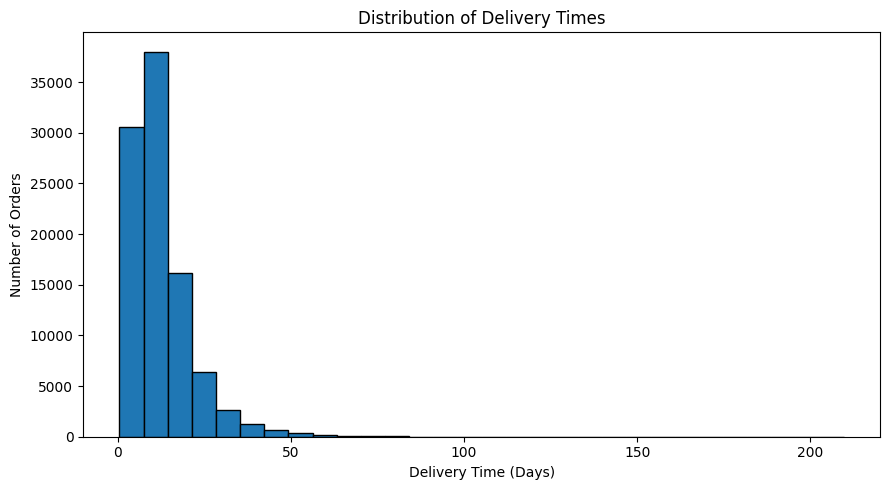

In [13]:
plt.figure(figsize=(9, 5))

plt.hist(
    delivered["delivery_days"].dropna(),
    bins=30,
    edgecolor="black")

plt.title("Distribution of Delivery Times")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()